In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import zipfile
import os

# Show the files uploaded to Colab
print(os.listdir('/content'))

['.config', 'archive (2).zip', 'sample_data']


In [4]:
import zipfile
import os

zip_path = '/content/archive (2).zip'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall('/content/shopping_data')

print(os.listdir('/content/shopping_data'))

['shopping_trends.csv', 'shopping_trends_updated.csv']


In [5]:
import pandas as pd

df = pd.read_csv('/content/shopping_data/shopping_trends_updated.csv')

df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (3900, 18)


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [8]:
print(df.columns.tolist())

['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category', 'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season', 'Review Rating', 'Subscription Status', 'Shipping Type', 'Discount Applied', 'Promo Code Used', 'Previous Purchases', 'Payment Method', 'Frequency of Purchases']


In [9]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64

Total Missing Values: 0


In [10]:
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:", duplicate_count)

Number of Duplicate Rows: 0


In [11]:
df.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [12]:
total_purchase = df['Purchase Amount (USD)'].sum()
average_purchase = df['Purchase Amount (USD)'].mean()
median_purchase = df['Purchase Amount (USD)'].median()

print(f"Total Purchase Amount: ${total_purchase:,.2f}")
print(f"Average Purchase Amount: ${average_purchase:.2f}")
print(f"Median Purchase Amount: ${median_purchase:.2f}")

Total Purchase Amount: $233,081.00
Average Purchase Amount: $59.76
Median Purchase Amount: $60.00


In [13]:
category_sales = (
    df.groupby('Category')['Purchase Amount (USD)']
    .agg(['sum', 'mean', 'count'])
    .sort_values('sum', ascending=False)
)

category_sales

,sum,mean,count
Category,,,
Clothing,104264,60.025331,1737
Accessories,74200,59.838710,1240
Footwear,36093,60.255426,599
Outerwear,18524,57.172840,324


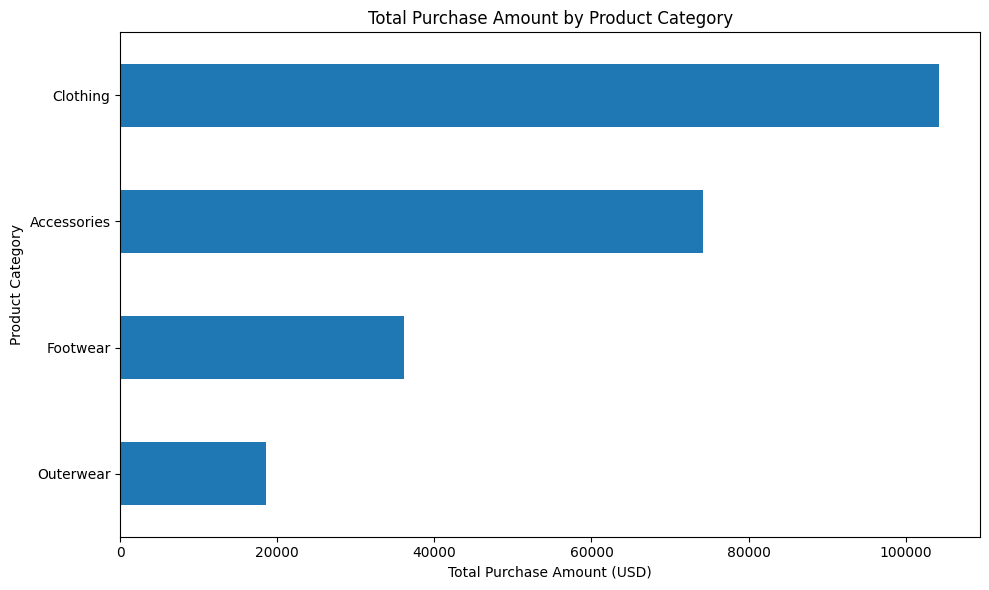

In [14]:
plt.figure(figsize=(10, 6))

category_sales['sum'].sort_values().plot(kind='barh')

plt.title('Total Purchase Amount by Product Category')
plt.xlabel('Total Purchase Amount (USD)')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [15]:
top_products = df['Item Purchased'].value_counts().head(10)

print("Top 10 Most Frequently Purchased Products:")
print(top_products)

Top 10 Most Frequently Purchased Products:
Item Purchased
Blouse        171
Pants         171
Jewelry       171
Shirt         169
Dress         166
Sweater       164
Jacket        163
Coat          161
Sunglasses    161
Belt          161
Name: count, dtype: int64


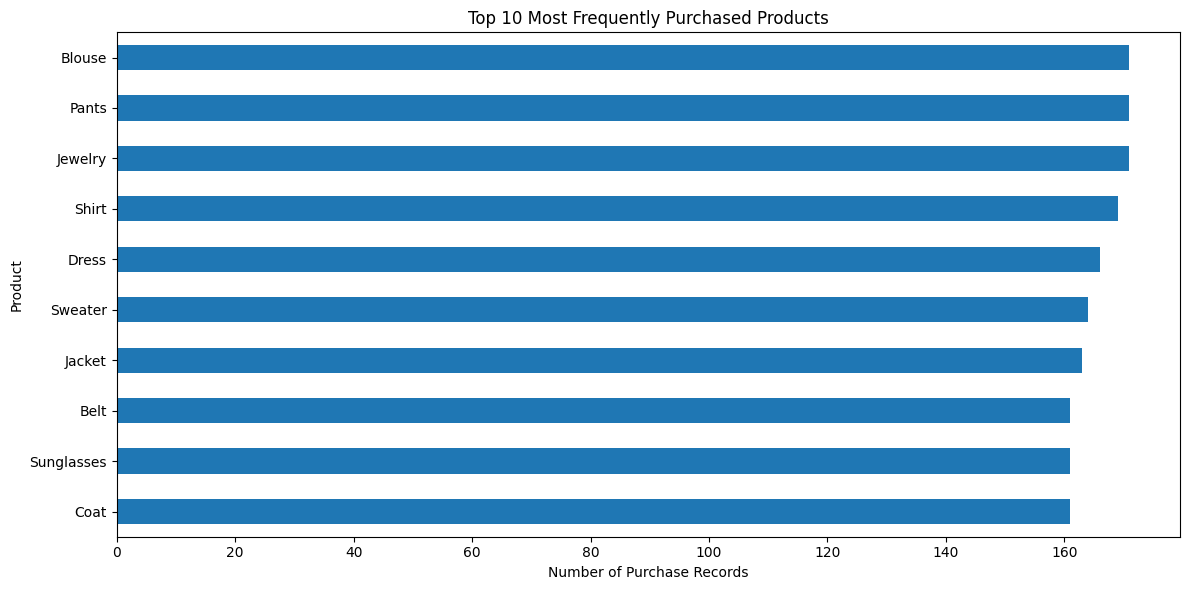

In [16]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind='barh')

plt.title('Top 10 Most Frequently Purchased Products')
plt.xlabel('Number of Purchase Records')
plt.ylabel('Product')

plt.tight_layout()
plt.show()

In [17]:
payment_counts = df['Payment Method'].value_counts()

print("Purchase Records by Payment Method:")
print(payment_counts)

Purchase Records by Payment Method:
Payment Method
PayPal           677
Credit Card      671
Cash             670
Debit Card       636
Venmo            634
Bank Transfer    612
Name: count, dtype: int64


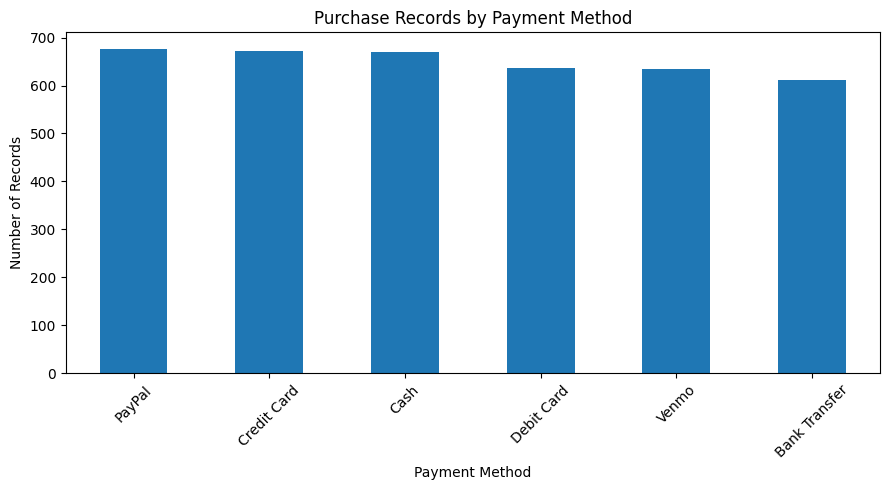

In [18]:
plt.figure(figsize=(9, 5))

payment_counts.plot(kind='bar')

plt.title('Purchase Records by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Records')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
gender_analysis = df.groupby('Gender').agg(
    Number_of_Records=('Customer ID', 'count'),
    Average_Purchase=('Purchase Amount (USD)', 'mean'),
    Total_Purchase=('Purchase Amount (USD)', 'sum')
)

gender_analysis

,Number_of_Records,Average_Purchase,Total_Purchase
Gender,,,
Female,1248,60.249199,75191
Male,2652,59.536199,157890


In [20]:
df['Age Group'] = pd.cut(
    df['Age'],
    bins=[0, 20, 30, 40, 50, 100],
    labels=['Under 20', '20-30', '31-40', '41-50', 'Above 50'],
    include_lowest=True
)

age_analysis = df.groupby(
    'Age Group',
    observed=False
).agg(
    Number_of_Records=('Customer ID', 'count'),
    Average_Purchase=('Purchase Amount (USD)', 'mean'),
    Total_Purchase=('Purchase Amount (USD)', 'sum')
)

age_analysis

,Number_of_Records,Average_Purchase,Total_Purchase
Age Group,,,
Under 20,212,58.981132,12504
20-30,737,60.753053,44775
31-40,725,59.576552,43193
41-50,750,58.838667,44129
Above 50,1476,59.945799,88480


In [21]:
season_analysis = df.groupby('Season').agg(
    Number_of_Records=('Customer ID', 'count'),
    Average_Purchase=('Purchase Amount (USD)', 'mean'),
    Total_Purchase=('Purchase Amount (USD)', 'sum')
).sort_values('Total_Purchase', ascending=False)

season_analysis

,Number_of_Records,Average_Purchase,Total_Purchase
Season,,,
Fall,975,61.556923,60018
Spring,999,58.737738,58679
Winter,971,60.357364,58607
Summer,955,58.405236,55777


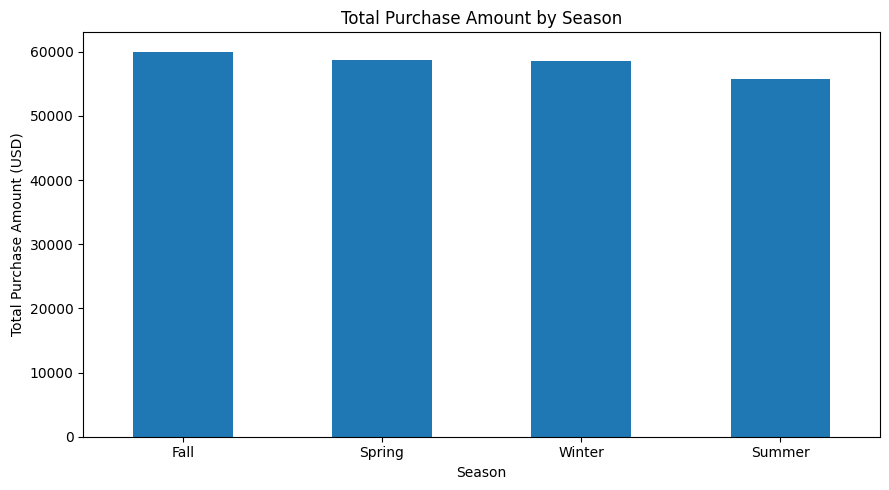

In [22]:
plt.figure(figsize=(9, 5))

season_analysis['Total_Purchase'].plot(kind='bar')

plt.title('Total Purchase Amount by Season')
plt.xlabel('Season')
plt.ylabel('Total Purchase Amount (USD)')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [23]:
print("Average Review Rating:", df['Review Rating'].mean())

print("\nReview Rating Statistics:")
print(df['Review Rating'].describe())

Average Review Rating: 3.7499487179487176

Review Rating Statistics:
count    3900.000000
mean        3.749949
std         0.716223
min         2.500000
25%         3.100000
50%         3.700000
75%         4.400000
max         5.000000
Name: Review Rating, dtype: float64


In [24]:
discount_analysis = df.groupby('Discount Applied').agg(
    Number_of_Records=('Customer ID', 'count'),
    Average_Purchase=('Purchase Amount (USD)', 'mean'),
    Total_Purchase=('Purchase Amount (USD)', 'sum')
)

discount_analysis

,Number_of_Records,Average_Purchase,Total_Purchase
Discount Applied,,,
No,2223,60.130454,133670
Yes,1677,59.279070,99411


In [25]:
subscription_analysis = df.groupby('Subscription Status').agg(
    Number_of_Records=('Customer ID', 'count'),
    Average_Purchase=('Purchase Amount (USD)', 'mean'),
    Total_Purchase=('Purchase Amount (USD)', 'sum')
)

subscription_analysis

,Number_of_Records,Average_Purchase,Total_Purchase
Subscription Status,,,
No,2847,59.865121,170436
Yes,1053,59.491928,62645


# Customer Shopping Analysis Dashboard

### Key Performance Indicators (KPIs)

Total Customers: 3,900
Total Shopping Records: 3,900
Total Purchase Amount: $233,081.00
Average Purchase Amount: $59.76
Average Review Rating: 3.75 / 5


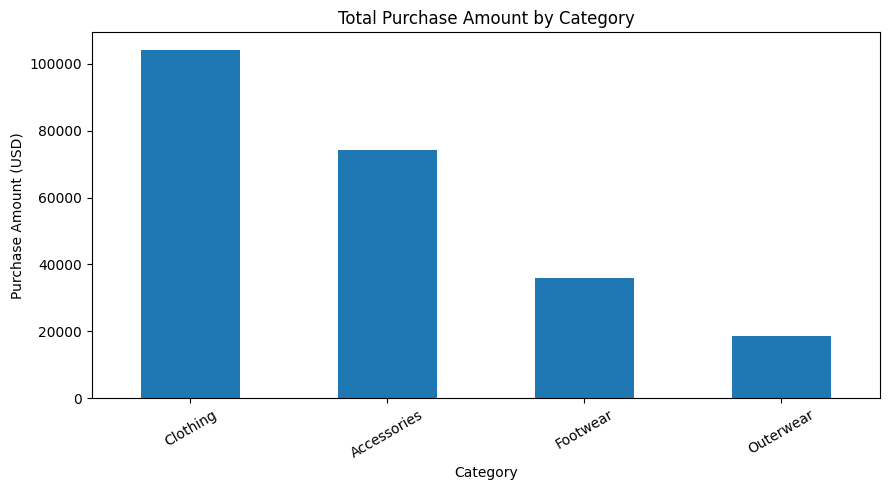

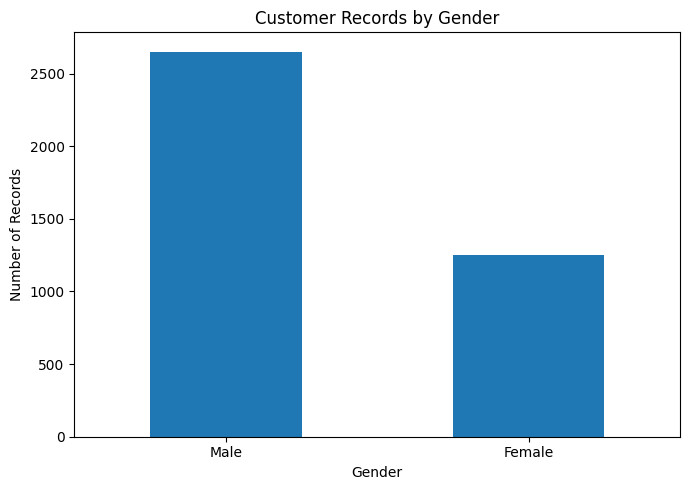

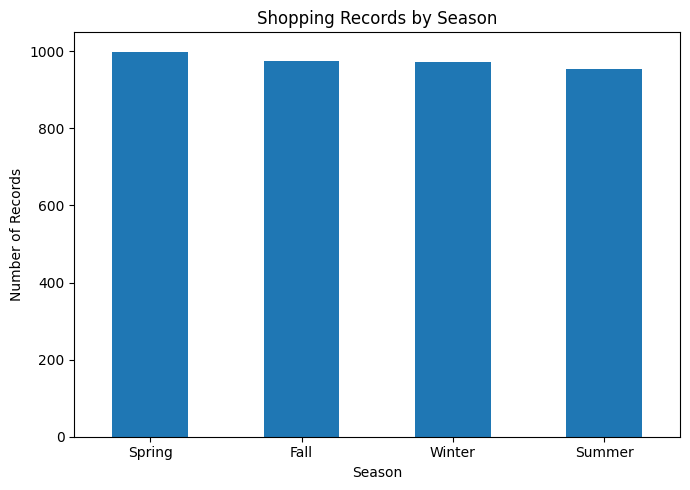

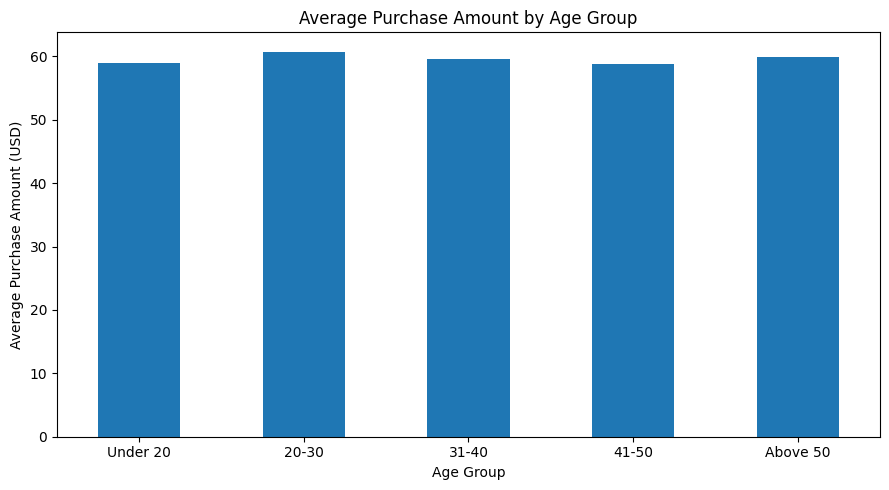


Dashboard completed successfully!


In [26]:
# ==========================================
# CUSTOMER SHOPPING ANALYSIS DASHBOARD
# ==========================================

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# 1. Calculate Key Performance Indicators (KPIs)

total_customers = df['Customer ID'].nunique()
total_records = len(df)
total_purchase = df['Purchase Amount (USD)'].sum()
average_purchase = df['Purchase Amount (USD)'].mean()
average_rating = df['Review Rating'].mean()

# 2. Display Dashboard Title

display(Markdown("# Customer Shopping Analysis Dashboard"))
display(Markdown("### Key Performance Indicators (KPIs)"))

print(f"Total Customers: {total_customers:,}")
print(f"Total Shopping Records: {total_records:,}")
print(f"Total Purchase Amount: ${total_purchase:,.2f}")
print(f"Average Purchase Amount: ${average_purchase:.2f}")
print(f"Average Review Rating: {average_rating:.2f} / 5")

# 3. Purchase Amount by Category

category_sales = df.groupby('Category')['Purchase Amount (USD)'].sum()
category_sales = category_sales.sort_values(ascending=False)

plt.figure(figsize=(9, 5))
category_sales.plot(kind='bar')
plt.title('Total Purchase Amount by Category')
plt.xlabel('Category')
plt.ylabel('Purchase Amount (USD)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 4. Customer Distribution by Gender

gender_counts = df['Gender'].value_counts()

plt.figure(figsize=(7, 5))
gender_counts.plot(kind='bar')
plt.title('Customer Records by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 5. Shopping Records by Season

season_counts = df['Season'].value_counts()

plt.figure(figsize=(7, 5))
season_counts.plot(kind='bar')
plt.title('Shopping Records by Season')
plt.xlabel('Season')
plt.ylabel('Number of Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. Average Purchase by Age Group

if 'Age Group' not in df.columns:
    df['Age Group'] = pd.cut(
        df['Age'],
        bins=[0, 20, 30, 40, 50, 100],
        labels=['Under 20', '20-30', '31-40', '41-50', 'Above 50'],
        include_lowest=True
    )

age_purchase = df.groupby(
    'Age Group', observed=False
)['Purchase Amount (USD)'].mean()

plt.figure(figsize=(9, 5))
age_purchase.plot(kind='bar')
plt.title('Average Purchase Amount by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Purchase Amount (USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("\nDashboard completed successfully!")

In [27]:
# ==========================================
# BUSINESS INSIGHTS
# ==========================================

print("=" * 50)
print("CUSTOMER SHOPPING BUSINESS INSIGHTS")
print("=" * 50)

# Insight 1: Best-selling category by total purchase amount
category_sales = df.groupby('Category')['Purchase Amount (USD)'].sum()
best_category = category_sales.idxmax()

print("\n1. Top Category by Purchase Amount:")
print(f"{best_category}: ${category_sales.max():,.2f}")

# Insight 2: Most frequently purchased item
popular_item = df['Item Purchased'].value_counts().idxmax()
popular_item_count = df['Item Purchased'].value_counts().max()

print("\n2. Most Frequently Recorded Item:")
print(f"{popular_item}: {popular_item_count} records")

# Insight 3: Most common payment method
payment_counts = df['Payment Method'].value_counts()
popular_payment = payment_counts.idxmax()

print("\n3. Most Common Payment Method:")
print(f"{popular_payment}: {payment_counts.max()} records")

# Insight 4: Highest-spending season by total purchase amount
season_sales = df.groupby('Season')['Purchase Amount (USD)'].sum()
best_season = season_sales.idxmax()

print("\n4. Season with the Highest Total Purchase Amount:")
print(f"{best_season}: ${season_sales.max():,.2f}")

# Insight 5: Subscription status distribution
subscription_counts = df['Subscription Status'].value_counts()
popular_subscription_status = subscription_counts.idxmax()

print("\n5. Most Common Subscription Status:")
print(
    f"{popular_subscription_status}: "
    f"{subscription_counts.max()} records"
)

# Insight 6: Overall customer review rating
average_rating = df['Review Rating'].mean()

print("\n6. Average Review Rating:")
print(f"{average_rating:.2f} out of 5")

print("\n" + "=" * 50)
print("BUSINESS INSIGHTS GENERATED SUCCESSFULLY!")
print("=" * 50)

CUSTOMER SHOPPING BUSINESS INSIGHTS

1. Top Category by Purchase Amount:
Clothing: $104,264.00

2. Most Frequently Recorded Item:
Blouse: 171 records

3. Most Common Payment Method:
PayPal: 677 records

4. Season with the Highest Total Purchase Amount:
Fall: $60,018.00

5. Most Common Subscription Status:
No: 2847 records

6. Average Review Rating:
3.75 out of 5

BUSINESS INSIGHTS GENERATED SUCCESSFULLY!


# Customer Shopping Analysis Using Python

## Project Overview

This project analyzes customer shopping trends using Python to identify purchasing patterns, popular products, payment preferences, seasonal trends, and customer subscription behavior.

## Tools and Libraries

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Google Colab

## Dataset

The project uses the Customer Shopping Trends Dataset, containing 3,900 records and 18 original columns related to customer demographics, purchased products, spending amounts, payment methods, seasons, and customer reviews.

## Key Findings

* Clothing recorded the highest total purchase amount at $104,264.
* Blouse was the most frequently recorded item, with 171 records.
* PayPal was the most frequently recorded payment method, appearing in 677 records.
* Fall had the highest total purchase amount among the seasons, at $60,018.
* The most common subscription status was "No," appearing in 2,847 records.
* The average customer review rating was 3.75 out of 5.

## Analysis Performed

* Data inspection and quality checks
* Summary statistics
* Purchase analysis by product category
* Product popularity analysis
* Payment method analysis
* Customer analysis by gender and age group
* Seasonal shopping analysis
* Customer review analysis
* Discount and subscription analysis
* Dashboard visualization
* Business insights

## Conclusion

The analysis highlights differences in purchasing activity across product categories, seasons, and payment methods. These findings can help a retailer investigate product demand, improve marketing campaigns, and develop strategies to encourage customer subscriptions.

## Author

Habiba Mohmed
